# Data Analytics (DA) 
##  Module-End -5  Assignment: Python For Data Analysis
###   “Social Media Engagement Analytics”

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


### Assignment Tasks
#### ❖Task 1 — Data Import & Setup

In [3]:
df=pd.read_csv(r"C:\Users\sumit\Downloads\archive\Social Media Engagement Dataset.csv")

df

,post_id,timestamp,day_of_week,platform,user_id,location,language,text_content,hashtags,mentions,...,comments_count,impressions,engagement_rate,brand_name,product_name,campaign_name,campaign_phase,user_past_sentiment_avg,user_engagement_growth,buzz_change_rate
0,kcqbs6hxybia,2024-12-09 11:26:15,Monday,Instagram,user_52nwb0a6,"Melbourne, Australia",pt,Just tried the Chromebook from Google. Best pu...,#Food,NaN,...,701,18991,0.19319,Google,Chromebook,BlackFriday,Launch,0.0953,-0.3672,19.1
1,vkmervg4ioos,2024-07-28 19:59:26,Sunday,Twitter,user_ucryct98,"Tokyo, Japan",ru,Just saw an ad for Microsoft Surface Laptop du...,"#MustHave, #Food","@CustomerService, @BrandCEO",...,359,52764,0.05086,Microsoft,Surface Laptop,PowerRelease,Post-Launch,0.1369,-0.4510,-42.6
2,memhx4o1x6yu,2024-11-23 14:00:12,Saturday,Reddit,user_7rrev126,"Beijing, China",ru,What's your opinion about Nike's Epic React? ...,"#Promo, #Food, #Trending",NaN,...,643,8887,0.45425,Nike,Epic React,BlackFriday,Post-Launch,0.2855,-0.4112,17.4
3,bhyo6piijqt9,2024-09-16 04:35:25,Monday,YouTube,user_4mxuq0ax,"Lagos, Nigeria",en,Bummed out with my new Diet Pepsi from Pepsi! ...,"#Reviews, #Sustainable","@StyleGuide, @BrandSupport",...,743,6696,0.42293,Pepsi,Diet Pepsi,LaunchWave,Launch,-0.2094,-0.0167,-5.5
4,c9dkiomowakt,2024-09-05 21:03:01,Thursday,Twitter,user_l1vpox2k,"Berlin, Germany",hi,Just tried the Corolla from Toyota. Absolutely...,"#Health, #Travel","@BrandSupport, @InfluencerName",...,703,47315,0.08773,Toyota,Corolla,LocalTouchpoints,Launch,0.6867,0.0807,38.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,vpqni584supc,2025-01-10 07:55:51,Friday,Instagram,user_ysobum87,"Seoul, South Korea",ar,Comparing Toyota Camry to the competition. Bes...,"#Food, #BestValue","@IndustryExpert, @InfluencerName",...,41,220,22.08636,Toyota,Camry,CustomerFirst,Pre-Launch,-0.0299,0.0205,-6.0
11996,h8rvov0xym5z,2024-12-04 18:50:38,Wednesday,Reddit,user_2jzngfsp,"New York, USA",pt,My two days review of Apple AirPods Pro: Highl...,#TrendAlert,"@TrendSetter, @NewsOutlet",...,176,17346,0.20546,Apple,AirPods Pro,FallCollection,Launch,0.5936,-0.0928,-92.1
11997,14zrjm51ea3y,2024-10-24 19:11:24,Thursday,Facebook,user_0sidyfyh,"Lyon, France",ja,Just unboxed my new Dri-FIT from Nike. Best pu...,#Food,"@RetailSupport, @TechHelp",...,330,90913,0.05342,Nike,Dri-FIT,LocalTouchpoints,Post-Launch,0.0899,-0.1186,-96.8
11998,7bdmnv3rdj8n,2024-11-12 03:07:19,Tuesday,Reddit,user_njyhr041,"Manchester, UK",fr,Comparing Toyota Camry to the competition. Doe...,"#SpecialOffer, #Promo, #Fashion","@BrandSupport, @TechHelp",...,221,78790,0.04732,Toyota,Camry,CyberMonday,Post-Launch,-0.3666,-0.4527,15.9


In [4]:
# Convert date columns to datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["timestamp"].dtype

dtype('<M8[us]')

In [7]:
# Use NumPy arrays for basic array operations
likes = df["likes_count"].to_numpy()
comments = df["comments_count"].to_numpy()
shares = df["shares_count"].to_numpy()
impr = df["impressions"].to_numpy()

print("array type/shape:",type(likes),likes.shape)
print("mean/median/std of likes:",np.mean(likes),np.median(likes),np.std(likes))
print("Maximum and Minimum likes:",likes.max(),likes.min())

array type/shape: <class 'numpy.ndarray'> (12000,)
mean/median/std of likes: 2490.72025 2496.0 1441.4724653364942
Maximum and Minimum likes: 5000 0


### ❖Task 2 — Data Cleaning

##### Cleaning Missing Data

In [17]:
df.isnull().sum()

post_id                       0
timestamp                     0
day_of_week                   0
platform                      0
user_id                       0
location                      0
language                      0
text_content                  0
hashtags                      0
mentions                   3941
keywords                      0
topic_category                0
sentiment_score               0
sentiment_label               0
emotion_type                  0
toxicity_score                0
likes_count                   0
shares_count                  0
comments_count                0
impressions                   0
engagement_rate               0
brand_name                    0
product_name                  0
campaign_name                 0
campaign_phase                0
user_past_sentiment_avg       0
user_engagement_growth        0
buzz_change_rate              0
dtype: int64

In [35]:
df["mentions"] = df["mentions"].fillna("")                 # fillna for text field
num_cols = df.select_dtypes("number").columns
cat_cols = df.select_dtypes(exclude="number").columns.drop(["timestamp", "mentions"])
df[num_cols] = df[num_cols].fillna(df[num_cols].median())  # median for numbers (no-op here)
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])                  # mode for categories (no-op here)
print("Missing values after cleaning:", int(df.isnull().sum().sum()))

Missing values after cleaning: 0


##### Duplicate Handling

In [21]:

print("duplicated:",df.duplicated().sum())


duplicated: 0


In [22]:
print("shape after handle duplicates:",df.shape)

shape after handle duplicates: (12000, 28)


##### Data Formatting

In [19]:
# Standardize categories
text_cols = ["platform", "sentiment_label", "emotion_type", "topic_category", "brand_name",
             "campaign_phase", "location", "day_of_week"]
for c in text_cols:
    df[c] = df[c].str.strip()
df["sentiment_label"] = df["sentiment_label"].str.title()
df["emotion_type"] = df["emotion_type"].str.title()

print("Sentiment labels:", sorted(df["sentiment_label"].unique()))
print("Emotions        :", sorted(df["emotion_type"].unique()))
print("Platforms       :", sorted(df["platform"].unique()))

# Consistency check
print("\nSentiment score range per label:")
print(df.groupby("sentiment_label")["sentiment_score"].agg(["min", "max", "mean", "count"]))

Sentiment labels: ['Negative', 'Neutral', 'Positive']
Emotions        : ['Angry', 'Confused', 'Excited', 'Happy', 'Sad']
Platforms       : ['Facebook', 'Instagram', 'Reddit', 'Twitter', 'YouTube']

Sentiment score range per label:
                    min     max      mean  count
sentiment_label                                 
Negative        -0.9998 -0.2004 -0.602139   4854
Neutral         -0.1999  0.1997 -0.001833   2307
Positive         0.2002  0.9999  0.606252   4839


In [4]:
# Correct unrealistic values in likes, comments, shares
count_cols = ["likes_count", "comments_count", "shares_count"]
print("Negative counts:", int((df[count_cols] < 0).sum().sum()))
print("Zero counts    :", (df[count_cols] == 0).sum().to_dict())
df[count_cols] = df[count_cols].clip(lower=0)

# engagement_rate above 100% means more interactions than impressions
print("\nRows with engagement_rate > 1 (over 100%):", int((df["engagement_rate"] > 1).sum()),
      f"({(df['engagement_rate'] > 1).mean():.1%})")
print("Max engagement_rate before fix:", df["engagement_rate"].max().round(2))
print("Impressions of those rows (median):", df.loc[df["engagement_rate"] > 1, "impressions"].median())

df["rate_over_100pct"] = df["engagement_rate"] > 1               # keep a flag for transparency
df["engagement_rate_clean"] = df["engagement_rate"].clip(upper=1)  # cap at 100%
print("Max engagement_rate_clean:", df["engagement_rate_clean"].max())

Negative counts: 0
Zero counts    : {'likes_count': 1, 'comments_count': 13, 'shares_count': 5}

Rows with engagement_rate > 1 (over 100%): 487 (4.1%)
Max engagement_rate before fix: 32.21
Impressions of those rows (median): 2133.0
Max engagement_rate_clean: 1.0


##### Feature Cleaning

In [5]:

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# 1. Text Metadata Features (Handling NaNs safely)
df["hashtag_count"] = df["hashtags"].fillna("").str.count("#")

# Replaced slow lambda loop with a vectorized string split/count strategy
df["mention_count"] = (
    df["mentions"]
    .fillna("")
    .str.split(",")
    .apply(lambda x: len([i for i in x if i.strip()])))

# 2. Location Features (Handling variations safely)
# Using expand=True safely splits locations even if commas are missing
loc_split = df["location"].fillna("").str.split(",", expand=True)
df["city"] = loc_split[0].str.strip()
df["country"] = (loc_split[loc_split.columns[-1]].str.strip() if not loc_split.empty else "")

# 3. Time-Based Features
df["date"] = df["timestamp"].dt.date
df["hour"] = df["timestamp"].dt.hour
df["month"] = df["timestamp"].dt.to_period("M").astype(str)

# Categorizing hour blocks
df["time_of_day"] = pd.cut(df["hour"],bins=[-1, 5, 11, 17, 23],labels=[ "Night (00-05)","Morning (06-11)","Afternoon (12-17)", "Evening (18-23)",],)
    
# Verification 
preview_cols = [ "hashtags", "hashtag_count","mentions", "mention_count", "location","country", "hour","time_of_day",]
print("--- Dataframe Preview ---")
print(df[preview_cols].head())

print("\n--- Hashtag Count Distribution ---")
print(df["hashtag_count"].value_counts().sort_index())

print(f"\nUnique Countries Identified: {df['country'].nunique()}")


--- Dataframe Preview ---
                   hashtags  hashtag_count                        mentions  \
0                     #Food              1                             NaN   
1          #MustHave, #Food              2     @CustomerService, @BrandCEO   
2  #Promo, #Food, #Trending              3                             NaN   
3    #Reviews, #Sustainable              2      @StyleGuide, @BrandSupport   
4          #Health, #Travel              2  @BrandSupport, @InfluencerName   

   mention_count              location    country  hour        time_of_day  
0              0  Melbourne, Australia  Australia    11    Morning (06-11)  
1              2          Tokyo, Japan      Japan    19    Evening (18-23)  
2              0        Beijing, China      China    14  Afternoon (12-17)  
3              2        Lagos, Nigeria    Nigeria     4      Night (00-05)  
4              2       Berlin, Germany    Germany    21    Evening (18-23)  

--- Hashtag Count Distribution ---
hashtag

### ❖Task 3 — Data Exploration using Pandas

In [6]:
df.head(5)

,post_id,timestamp,day_of_week,platform,user_id,location,language,text_content,hashtags,mentions,...,rate_over_100pct,engagement_rate_clean,hashtag_count,mention_count,city,country,date,hour,month,time_of_day
0,kcqbs6hxybia,2024-12-09 11:26:15,Monday,Instagram,user_52nwb0a6,"Melbourne, Australia",pt,Just tried the Chromebook from Google. Best pu...,#Food,NaN,...,False,0.19319,1,0,Melbourne,Australia,2024-12-09,11,2024-12,Morning (06-11)
1,vkmervg4ioos,2024-07-28 19:59:26,Sunday,Twitter,user_ucryct98,"Tokyo, Japan",ru,Just saw an ad for Microsoft Surface Laptop du...,"#MustHave, #Food","@CustomerService, @BrandCEO",...,False,0.05086,2,2,Tokyo,Japan,2024-07-28,19,2024-07,Evening (18-23)
2,memhx4o1x6yu,2024-11-23 14:00:12,Saturday,Reddit,user_7rrev126,"Beijing, China",ru,What's your opinion about Nike's Epic React? ...,"#Promo, #Food, #Trending",NaN,...,False,0.45425,3,0,Beijing,China,2024-11-23,14,2024-11,Afternoon (12-17)
3,bhyo6piijqt9,2024-09-16 04:35:25,Monday,YouTube,user_4mxuq0ax,"Lagos, Nigeria",en,Bummed out with my new Diet Pepsi from Pepsi! ...,"#Reviews, #Sustainable","@StyleGuide, @BrandSupport",...,False,0.42293,2,2,Lagos,Nigeria,2024-09-16,4,2024-09,Night (00-05)
4,c9dkiomowakt,2024-09-05 21:03:01,Thursday,Twitter,user_l1vpox2k,"Berlin, Germany",hi,Just tried the Corolla from Toyota. Absolutely...,"#Health, #Travel","@BrandSupport, @InfluencerName",...,False,0.08773,2,2,Berlin,Germany,2024-09-05,21,2024-09,Evening (18-23)


In [7]:
df.tail(5)

,post_id,timestamp,day_of_week,platform,user_id,location,language,text_content,hashtags,mentions,...,rate_over_100pct,engagement_rate_clean,hashtag_count,mention_count,city,country,date,hour,month,time_of_day
11995,vpqni584supc,2025-01-10 07:55:51,Friday,Instagram,user_ysobum87,"Seoul, South Korea",ar,Comparing Toyota Camry to the competition. Bes...,"#Food, #BestValue","@IndustryExpert, @InfluencerName",...,True,1.00000,2,2,Seoul,South Korea,2025-01-10,7,2025-01,Morning (06-11)
11996,h8rvov0xym5z,2024-12-04 18:50:38,Wednesday,Reddit,user_2jzngfsp,"New York, USA",pt,My two days review of Apple AirPods Pro: Highl...,#TrendAlert,"@TrendSetter, @NewsOutlet",...,False,0.20546,1,2,New York,USA,2024-12-04,18,2024-12,Evening (18-23)
11997,14zrjm51ea3y,2024-10-24 19:11:24,Thursday,Facebook,user_0sidyfyh,"Lyon, France",ja,Just unboxed my new Dri-FIT from Nike. Best pu...,#Food,"@RetailSupport, @TechHelp",...,False,0.05342,1,2,Lyon,France,2024-10-24,19,2024-10,Evening (18-23)
11998,7bdmnv3rdj8n,2024-11-12 03:07:19,Tuesday,Reddit,user_njyhr041,"Manchester, UK",fr,Comparing Toyota Camry to the competition. Doe...,"#SpecialOffer, #Promo, #Fashion","@BrandSupport, @TechHelp",...,False,0.04732,3,2,Manchester,UK,2024-11-12,3,2024-11,Night (00-05)
11999,28cbflmapxbj,2024-05-15 20:07:23,Wednesday,Reddit,user_gbxy87di,"Tokyo, Japan",zh,Just saw an ad for Apple iMac during the Innov...,"#Sale, #Fitness",@MarketingTeam,...,False,0.01828,2,1,Tokyo,Japan,2024-05-15,20,2024-05,Evening (18-23)


In [8]:
print(df.shape)

(12000, 38)


In [9]:
print(list(df.columns))

['post_id', 'timestamp', 'day_of_week', 'platform', 'user_id', 'location', 'language', 'text_content', 'hashtags', 'mentions', 'keywords', 'topic_category', 'sentiment_score', 'sentiment_label', 'emotion_type', 'toxicity_score', 'likes_count', 'shares_count', 'comments_count', 'impressions', 'engagement_rate', 'brand_name', 'product_name', 'campaign_name', 'campaign_phase', 'user_past_sentiment_avg', 'user_engagement_growth', 'buzz_change_rate', 'rate_over_100pct', 'engagement_rate_clean', 'hashtag_count', 'mention_count', 'city', 'country', 'date', 'hour', 'month', 'time_of_day']


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 38 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   post_id                  12000 non-null  str           
 1   timestamp                12000 non-null  datetime64[us]
 2   day_of_week              12000 non-null  str           
 3   platform                 12000 non-null  str           
 4   user_id                  12000 non-null  str           
 5   location                 12000 non-null  str           
 6   language                 12000 non-null  str           
 7   text_content             12000 non-null  str           
 8   hashtags                 12000 non-null  str           
 9   mentions                 8059 non-null   str           
 10  keywords                 12000 non-null  str           
 11  topic_category           12000 non-null  str           
 12  sentiment_score          12000 non-null  fl

In [13]:
df[[
    "likes_count", 
    "comments_count", 
    "shares_count", 
    "impressions", 
    "engagement_rate",
    "engagement_rate_clean", 
    "sentiment_score", 
    "toxicity_score"
]].describe()

,likes_count,comments_count,shares_count,impressions,engagement_rate,engagement_rate_clean,sentiment_score,toxicity_score
count,12000.00000,12000.00000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,2490.72025,504.34575,1007.167167,49811.338500,0.278137,0.167641,0.000553,0.503868
std,1441.53253,288.68416,575.072282,28930.289451,1.149206,0.227891,0.583563,0.288198
min,0.00000,0.00000,0.000000,130.000000,0.001880,0.001880,-0.999800,0.000000
25%,1236.00000,253.00000,510.000000,24716.500000,0.049100,0.049100,-0.503200,0.251400
50%,2496.00000,503.00000,1018.000000,49674.000000,0.080605,0.080605,-0.006200,0.505950
75%,3723.25000,755.00000,1501.000000,74815.000000,0.163123,0.163123,0.513525,0.756200
max,5000.00000,1000.00000,2000.000000,99997.000000,32.211710,1.000000,0.999900,0.999900


In [14]:
# categorical distribution
for c in ["platform", "topic_category", "sentiment_label", "emotion_type", "campaign_phase", "country"]:
    print(f"--- {c}  (nunique = {df[c].nunique()}) ---")
    print(df[c].value_counts().head(8).to_string(), "\n")
print("Unique brands:", df["brand_name"].unique())

--- platform  (nunique = 5) ---
platform
YouTube      2436
Facebook     2431
Twitter      2406
Reddit       2372
Instagram    2355 

--- topic_category  (nunique = 6) ---
topic_category
Pricing      2046
Marketing    2043
Delivery     2036
Returns      1991
Support      1947
Product      1937 

--- sentiment_label  (nunique = 3) ---
sentiment_label
Negative    4854
Positive    4839
Neutral     2307 

--- emotion_type  (nunique = 5) ---
emotion_type
Sad         2504
Excited     2436
Confused    2393
Happy       2350
Angry       2317 

--- campaign_phase  (nunique = 3) ---
campaign_phase
Pre-Launch     4006
Launch         4004
Post-Launch    3990 

--- country  (nunique = 18) ---
country
USA        1460
China       765
Italy       752
Germany     748
Brazil      735
India       734
UK          728
Canada      724 

Unique brands: <ArrowStringArray>
[   'Google', 'Microsoft',      'Nike',     'Pepsi',    'Toyota', 'Coca-Cola',
    'Amazon',   'Samsung',    'Adidas',     'Apple']
Length: 1

In [15]:
# Correlation matrix of numeric fields
num_for_corr = ["likes_count", "comments_count", "shares_count", "impressions", "engagement_rate_clean",
                "sentiment_score", "toxicity_score", "hashtag_count", "user_past_sentiment_avg",
                "user_engagement_growth", "buzz_change_rate"]
corr = df[num_for_corr].corr()
corr.round(3)

,likes_count,comments_count,shares_count,impressions,engagement_rate_clean,sentiment_score,toxicity_score,hashtag_count,user_past_sentiment_avg,user_engagement_growth,buzz_change_rate
likes_count,1.000,0.007,0.003,0.002,0.206,-0.018,-0.009,0.002,0.003,0.013,0.011
comments_count,0.007,1.000,0.024,-0.009,0.047,0.007,-0.016,-0.023,-0.018,0.009,0.007
shares_count,0.003,0.024,1.000,-0.009,0.106,0.003,0.011,-0.010,0.006,-0.006,-0.007
impressions,0.002,-0.009,-0.009,1.000,-0.674,0.000,0.013,0.013,0.012,0.011,0.001
engagement_rate_clean,0.206,0.047,0.106,-0.674,1.000,-0.011,-0.009,-0.019,-0.008,-0.013,-0.009
sentiment_score,-0.018,0.007,0.003,0.000,-0.011,1.000,0.008,0.003,0.006,-0.012,-0.005
toxicity_score,-0.009,-0.016,0.011,0.013,-0.009,0.008,1.000,0.018,-0.007,-0.002,-0.004
hashtag_count,0.002,-0.023,-0.010,0.013,-0.019,0.003,0.018,1.000,0.000,0.010,0.000
user_past_sentiment_avg,0.003,-0.018,0.006,0.012,-0.008,0.006,-0.007,0.000,1.000,-0.003,0.007
user_engagement_growth,0.013,0.009,-0.006,0.011,-0.013,-0.012,-0.002,0.010,-0.003,1.000,0.001


In [17]:
# Group by summarise matrix
print("Average likes by platform:")
print(df.groupby("platform")["likes_count"].mean().sort_values(ascending=False).round(1).to_string())
print("\nTotal impressions by country (top 10):")
print(df.groupby("country")["impressions"].sum().sort_values(ascending=False).head(10).to_string())

Average likes by platform:
platform
Facebook     2522.9
Instagram    2506.0
Reddit       2497.9
YouTube      2481.8
Twitter      2445.2

Total impressions by country (top 10):
country
USA          72938671
China        38308970
Italy        38086357
Canada       36992563
India        36845626
Brazil       36798049
Germany      36309382
Japan        35955952
Australia    35794958
UK           35725280


### ❖Task 4 — Data Wrangling 

In [18]:
# New fields
df["total_interactions"] = df["likes_count"] + df["comments_count"] + df["shares_count"]
# Weighted score: comments and shares need more effort than a like, so they weigh more
df["engagement_score"] = df["likes_count"] + 2 * df["comments_count"] + 3 * df["shares_count"]
df["log_impressions"] = np.log1p(df["impressions"])
df["log_likes"] = np.log1p(df["likes_count"])
df["log_engagement_score"] = np.log1p(df["engagement_score"])
df[["likes_count", "comments_count", "shares_count", "total_interactions", "engagement_score",
    "log_engagement_score", "hashtag_count"]].head()

,likes_count,comments_count,shares_count,total_interactions,engagement_score,log_engagement_score,hashtag_count
0,1264,701,1704,3669,7778,8.959183,1
1,522,359,1803,2684,6649,8.802372,2
2,2689,643,705,4037,6090,8.714568,3
3,1827,743,262,2832,4099,8.318742,2
4,2005,703,1443,4151,7740,8.954286,2


In [19]:
# merge: build a country-level table and join it back to the posts
country_summary = (df.groupby("country")
                     .agg(posts=("post_id", "count"),
                          avg_engagement_rate=("engagement_rate_clean", "mean"),
                          avg_likes=("likes_count", "mean"))
                     .reset_index())
df = df.merge(country_summary[["country", "avg_engagement_rate"]]
                .rename(columns={"avg_engagement_rate": "country_avg_rate"}), on="country", how="left")
df["above_country_avg"] = df["engagement_rate_clean"] > df["country_avg_rate"]
print("Merged shape:", df.shape)
print(df["above_country_avg"].mean().round(3), "share of posts beat their country average")

# concat: stack the three campaign phases back together
phases = [g for _, g in df.groupby("campaign_phase")]
rebuilt = pd.concat(phases).sort_index()
print("concat check – same number of rows:", len(rebuilt) == len(df))

Merged shape: (12000, 45)
0.238 share of posts beat their country average
concat check – same number of rows: True


In [20]:
# groupby summaries by platform, country and sentiment
by_platform = df.groupby("platform").agg(posts=("post_id", "count"),
                                         avg_likes=("likes_count", "mean"),
                                         avg_engagement_score=("engagement_score", "mean"),
                                         avg_rate=("engagement_rate_clean", "mean"),
                                         median_rate=("engagement_rate_clean", "median")).round(3)
by_platform.sort_values("avg_engagement_score", ascending=False)

,posts,avg_likes,avg_engagement_score,avg_rate,median_rate
platform,,,,,
Instagram,2355,2506.006,6629.226,0.174,0.080
YouTube,2436,2481.823,6549.834,0.165,0.080
Reddit,2372,2497.914,6514.249,0.167,0.081
Facebook,2431,2522.874,6466.641,0.170,0.082
Twitter,2406,2445.187,6447.021,0.163,0.080


In [21]:
by_country = df.groupby("country").agg(posts=("post_id", "count"),
                                       avg_impressions=("impressions", "mean"),
                                       avg_rate=("engagement_rate_clean", "mean"),
                                       median_rate=("engagement_rate_clean", "median")).round(3)
by_country.sort_values("avg_rate", ascending=False)

,posts,avg_impressions,avg_rate,median_rate
country,,,,
South Korea,362,47870.409,0.194,0.089
Egypt,333,47739.435,0.184,0.080
UK,728,49073.187,0.177,0.082
Germany,748,48541.955,0.176,0.083
Spain,711,49090.785,0.176,0.085
Brazil,735,50065.373,0.172,0.080
China,765,50077.085,0.171,0.080
Australia,723,49508.932,0.170,0.081
Nigeria,342,48156.152,0.169,0.082


In [22]:
by_sentiment = df.groupby("sentiment_label").agg(posts=("post_id", "count"),
                                                 avg_likes=("likes_count", "mean"),
                                                 avg_comments=("comments_count", "mean"),
                                                 avg_shares=("shares_count", "mean"),
                                                 avg_impressions=("impressions", "mean"),
                                                 avg_rate=("engagement_rate_clean", "mean"),
                                                 median_rate=("engagement_rate_clean", "median"),
                                                 avg_toxicity=("toxicity_score", "mean")).round(3)
by_sentiment

,posts,avg_likes,avg_comments,avg_shares,avg_impressions,avg_rate,median_rate,avg_toxicity
sentiment_label,,,,,,,,
Negative,4854,2514.730,502.289,1007.256,49410.816,0.172,0.082,0.498
Neutral,2307,2471.072,502.773,998.408,50606.761,0.165,0.078,0.509
Positive,4839,2476.003,507.159,1011.254,49833.883,0.165,0.081,0.507


### ❖Task 5 — Statistical Analysis 

In [29]:
from scipy import stats
stat_cols = ["likes_count", "comments_count", "shares_count", "impressions",
             "engagement_rate", "engagement_rate_clean"]
rows = {}
for c in stat_cols:
    s = df[c]
    rows[c] = {"mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
               "std": s.std(), "variance": s.var(),
               "p10": s.quantile(.10), "p25": s.quantile(.25), "p75": s.quantile(.75),
               "p90": s.quantile(.90), "p99": s.quantile(.99),}
               
pd.DataFrame(rows).T.round(3)

,mean,median,mode,std,variance,p10,p25,p75,p90,p99
likes_count,2490.720,2496.000,3008.00,1441.533,2.078016e+06,499.900,1236.000,3723.250,4493.000,4950.010
comments_count,504.346,503.000,465.00,288.684,8.333854e+04,105.000,253.000,755.000,902.000,989.000
shares_count,1007.167,1018.000,612.00,575.072,3.307081e+05,210.000,510.000,1501.000,1803.000,1977.010
impressions,49811.338,49674.000,6623.00,28930.289,8.369616e+08,9525.400,24716.500,74815.000,90062.700,99192.140
engagement_rate,0.278,0.081,0.05,1.149,1.321000e+00,0.031,0.049,0.163,0.412,3.985
engagement_rate_clean,0.168,0.081,1.00,0.228,5.200000e-02,0.031,0.049,0.163,0.412,1.000


### ❖Task 6 — Data Visualization (Matplotlib, Seaborn, Plotly)

#### Matplotlib

##### Scatter: likes vs impressions

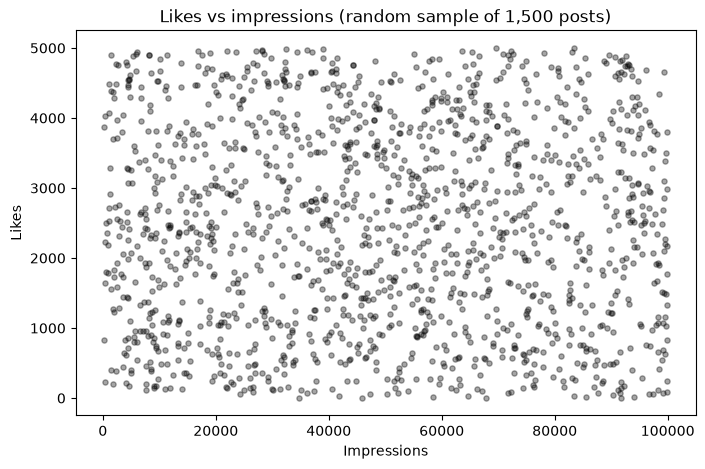

In [34]:
sample = df.sample(1500, random_state=42)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample["impressions"], sample["likes_count"], alpha=0.35, s=14, color="black")
ax.set_xlabel("Impressions"); ax.set_ylabel("Likes"); ax.set_title("Likes vs impressions (random sample of 1,500 posts)")
plt.show()

##### Line: daily engagement trend

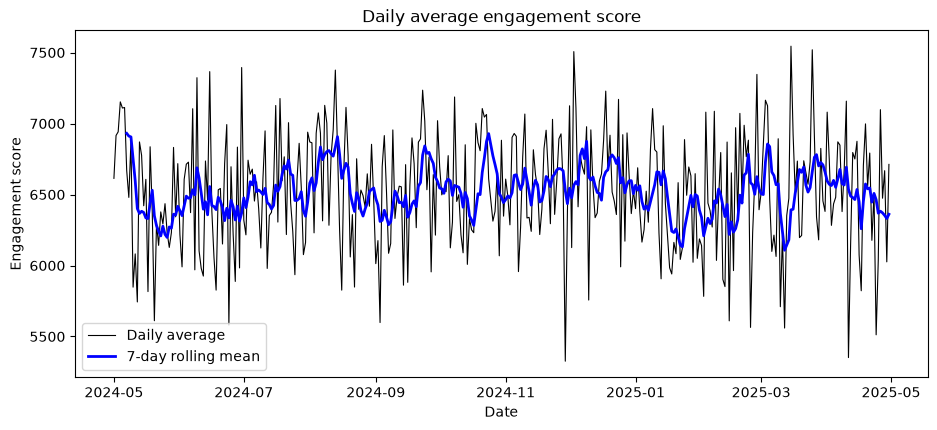

In [40]:
daily = df.groupby("date")["engagement_score"].mean()
daily.index = pd.to_datetime(daily.index)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily.index, daily.values, color="black", lw=0.8, label="Daily average")
ax.plot(daily.index, daily.rolling(7).mean(), color="blue", lw=2, label="7-day rolling mean")
ax.set_title("Daily average engagement score"); ax.set_xlabel("Date"); ax.set_ylabel("Engagement score"); ax.legend()
plt.show()

#####  Bar: posts by category

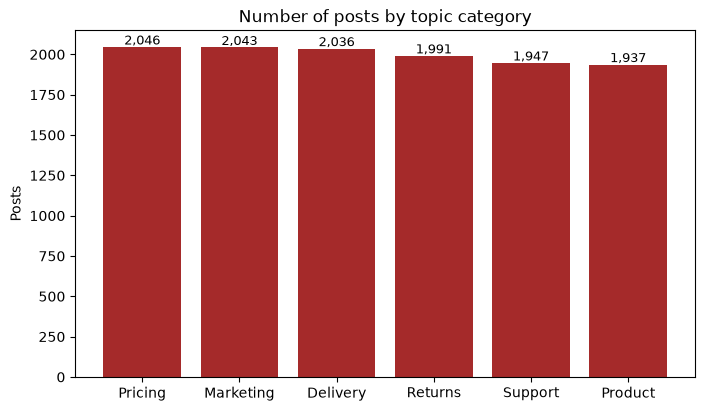

In [44]:
cat_counts = df["topic_category"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(cat_counts.index, cat_counts.values, color="brown")
ax.set_title("Number of posts by topic category"); ax.set_ylabel("Posts")
for i, v in enumerate(cat_counts.values):
    ax.text(i, v + 15, f"{v:,}", ha="center", fontsize=9)
plt.show()

##### Pie: gender distribution 

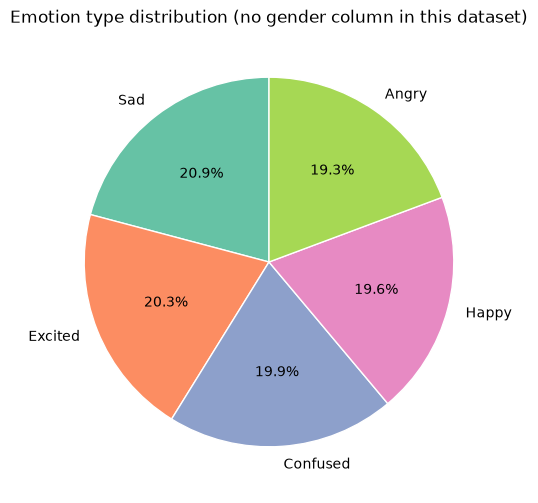

In [46]:

emo = df["emotion_type"].value_counts()
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(emo.values, labels=emo.index, autopct="%1.1f%%", startangle=90,
       colors=sns.color_palette("Set2", len(emo)), wedgeprops={"edgecolor": "white"})
ax.set_title("Emotion type distribution (no gender column in this dataset)")
plt.show()

#####  Histogram: age 

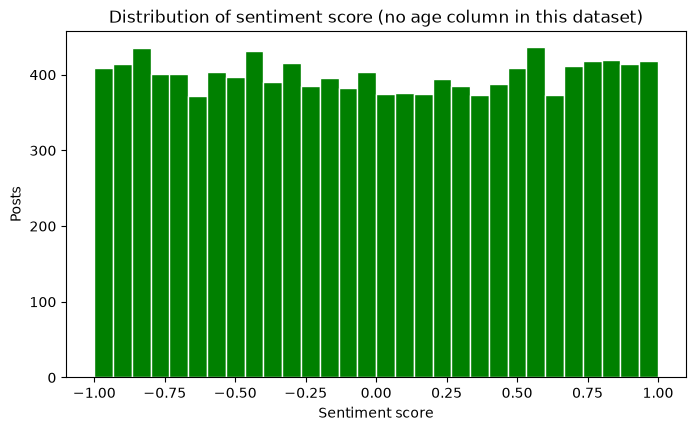

In [48]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["sentiment_score"], bins=30, color="green", edgecolor="white")
ax.set_title("Distribution of sentiment score (no age column in this dataset)")
ax.set_xlabel("Sentiment score"); ax.set_ylabel("Posts")
plt.show()

##### Box: engagement rate

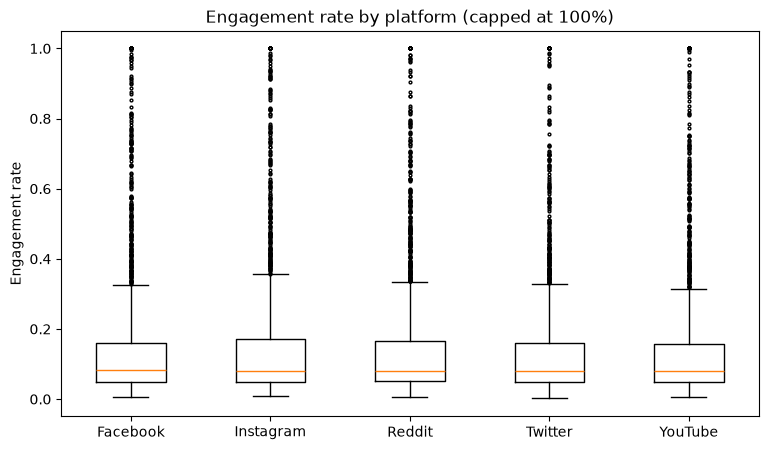

In [49]:
fig, ax = plt.subplots(figsize=(9, 5))
data = [g["engagement_rate_clean"].values for _, g in df.groupby("platform")]
ax.boxplot(data, showfliers=True, flierprops={"markersize": 2})
ax.set_xticklabels(sorted(df["platform"].unique()))
ax.set_title("Engagement rate by platform (capped at 100%)"); ax.set_ylabel("Engagement rate")
plt.show()

### Seaborn

##### Count plot: post type

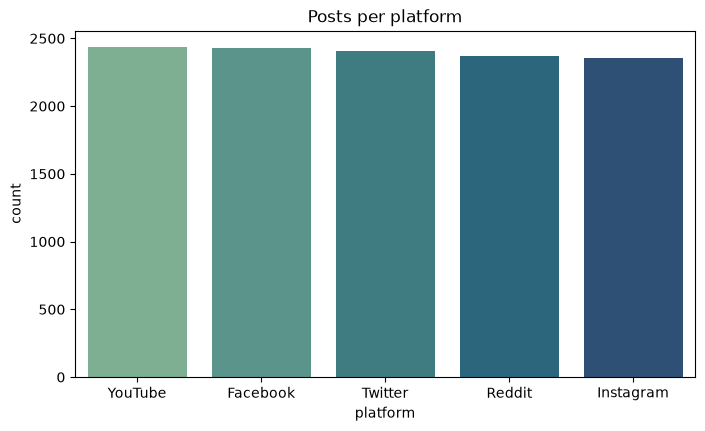

In [50]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, x="platform", order=df["platform"].value_counts().index, palette="", ax=ax)
ax.set_title("Posts per platform")
plt.show()

##### Bar plot: average likes by category

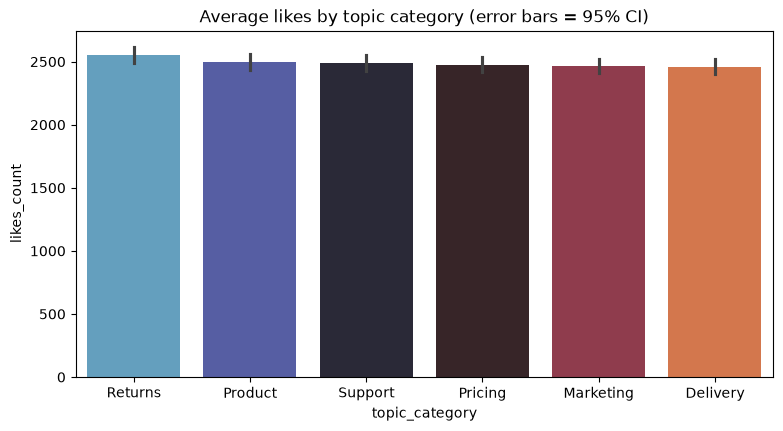

In [54]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = df.groupby("topic_category")["likes_count"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="topic_category", y="likes_count", order=order, palette="icefire", errorbar="ci", ax=ax)
ax.set_title("Average likes by topic category (error bars = 95% CI)")
plt.show()

##### Violin: followers vs sentiment

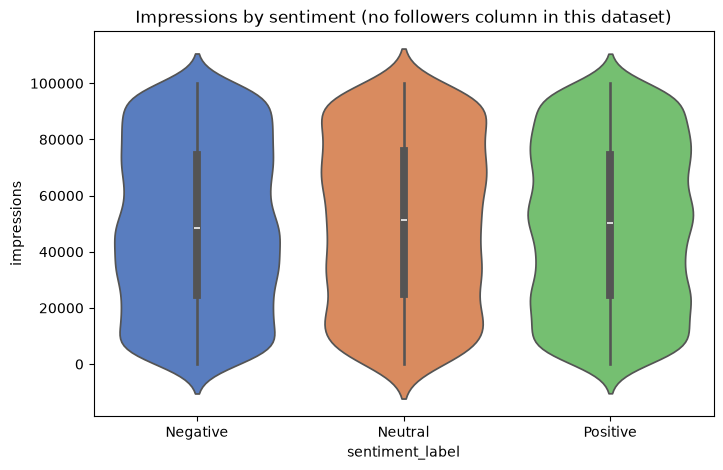

In [52]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df, x="sentiment_label", y="impressions", order=["Negative", "Neutral", "Positive"], palette="muted", ax=ax)
ax.set_title("Impressions by sentiment (no followers column in this dataset)")
plt.show()

##### Pair plot: numeric features

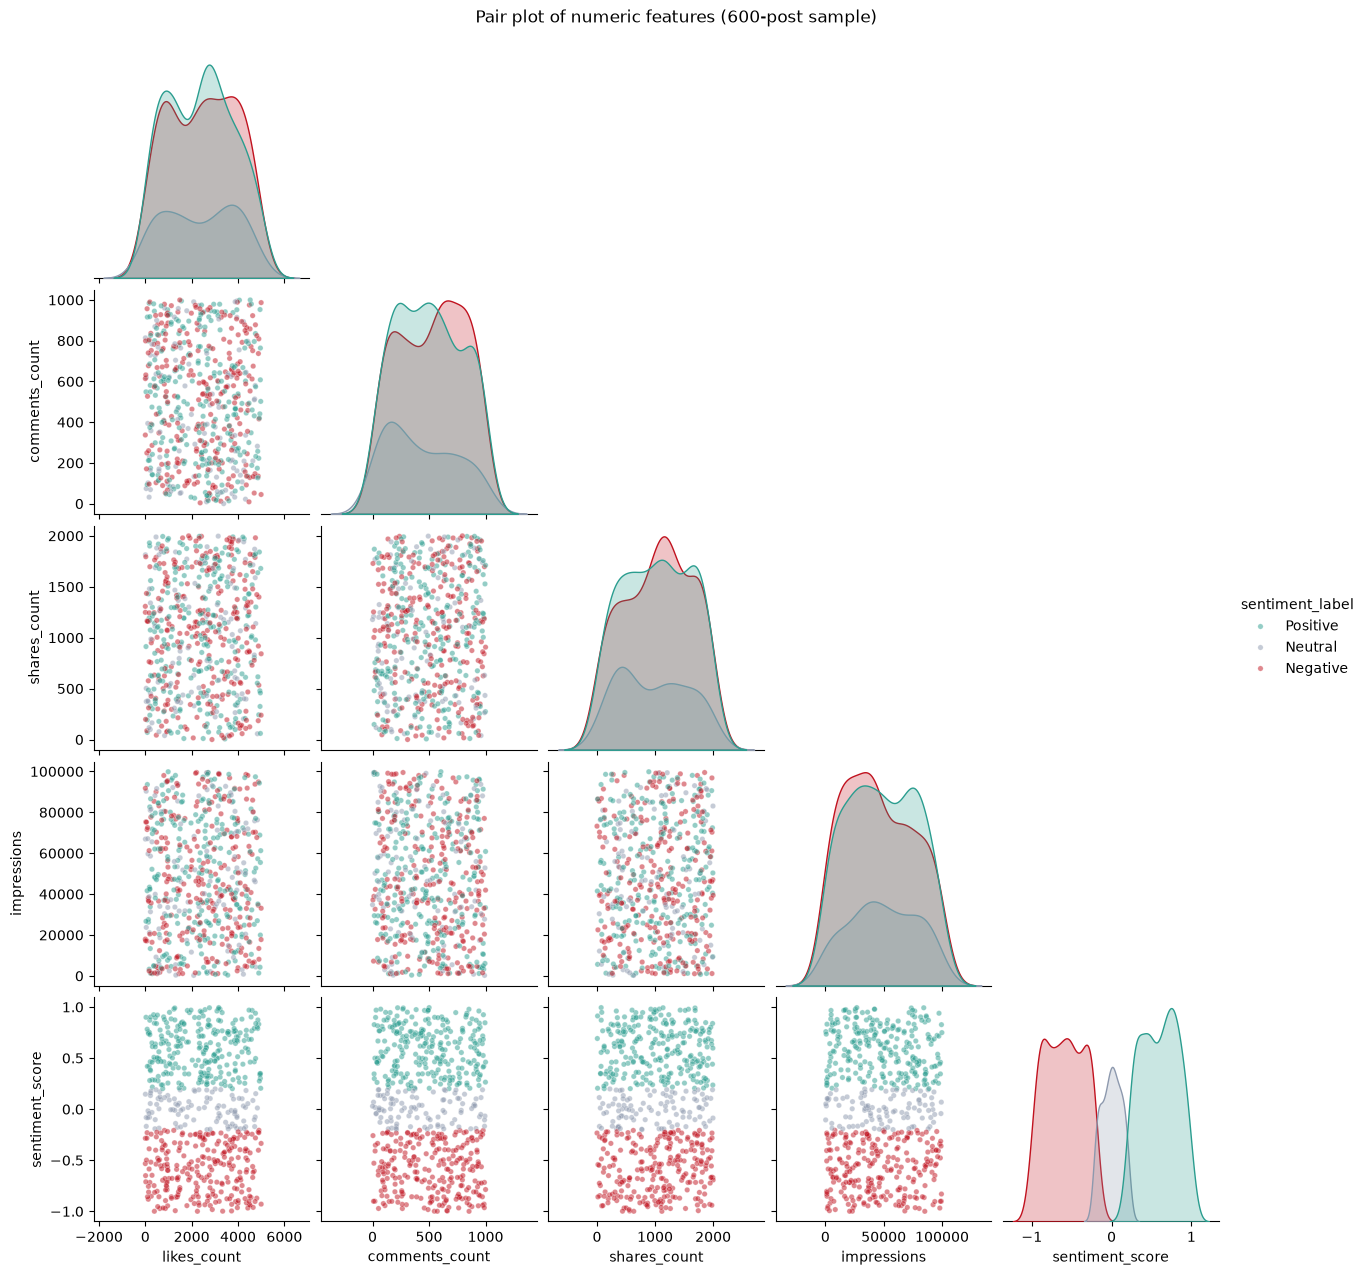

In [59]:
pp_cols = ["likes_count", "comments_count", "shares_count", "impressions", "sentiment_score"]
g = sns.pairplot(df.sample(600, random_state=1)[pp_cols + ["sentiment_label"]], hue="sentiment_label",
                 palette={"Negative": "#c1121f", "Neutral": "#8d99ae", "Positive": "#2a9d8f"},
                 plot_kws={"alpha": 0.5, "s": 15}, corner=True)
g.fig.suptitle("Pair plot of numeric features (600-post sample)", y=1.02)
plt.show()

##### Heatmap: correlation matrix

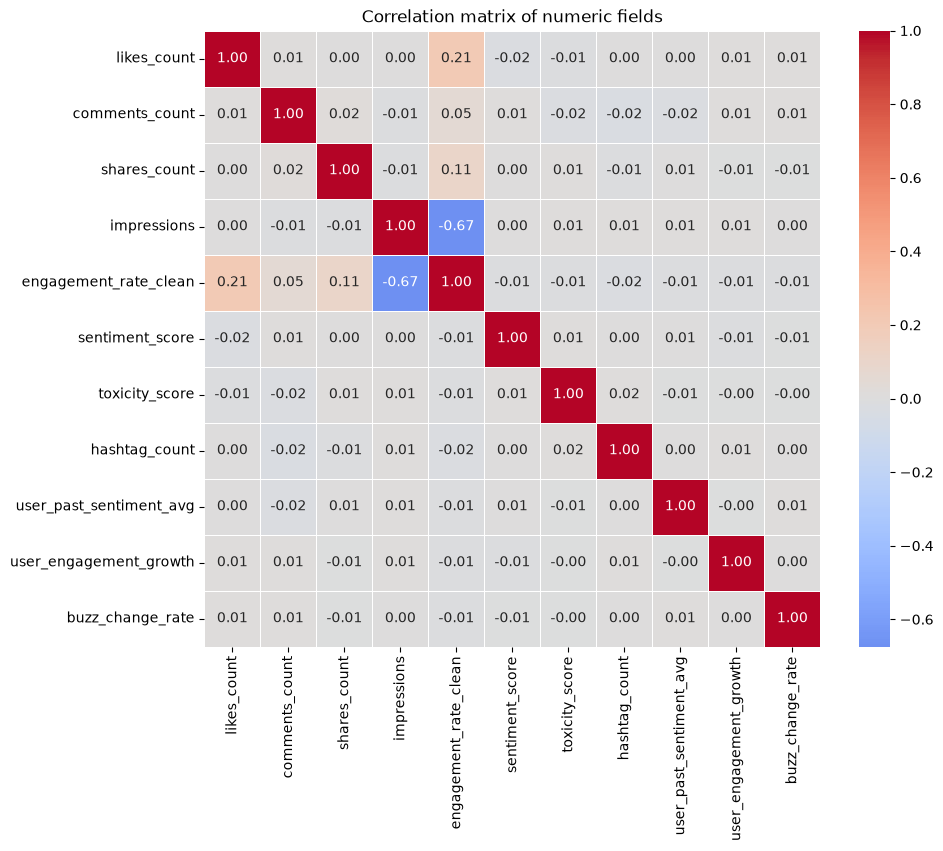

In [60]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5, ax=ax)
ax.set_title("Correlation matrix of numeric fields")
plt.show()

##### Swarm plot: engagement vs platform 

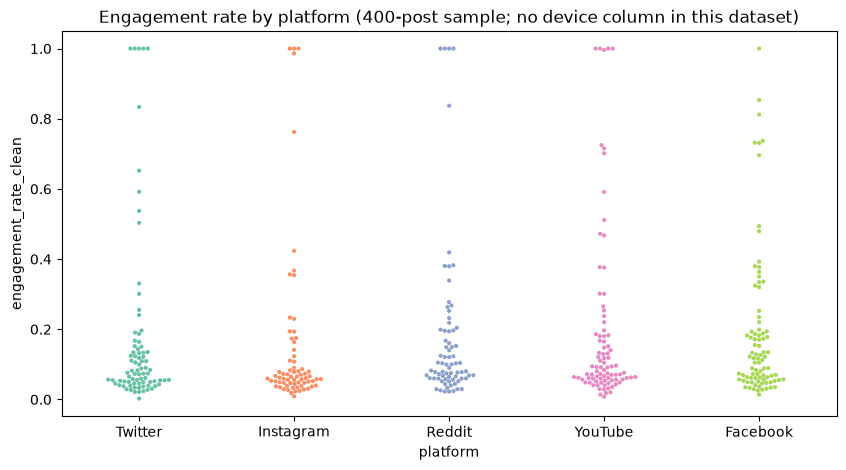

In [61]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.swarmplot(data=df.sample(400, random_state=3), x="platform", y="engagement_rate_clean", size=3, palette="Set2", ax=ax)
ax.set_title("Engagement rate by platform (400-post sample; no device column in this dataset)")
plt.show()

#### Plotly(interactive)

In [63]:
import plotly.express as px

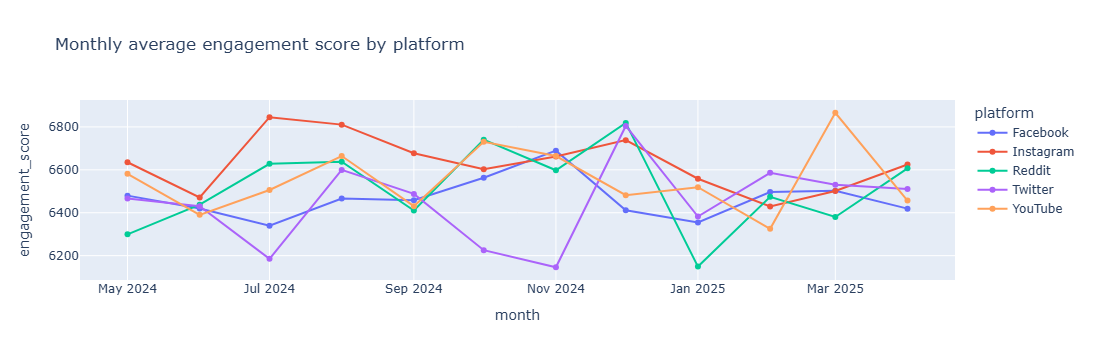

In [64]:
# Interactive line: monthly average engagement score per platform
monthly = df.groupby(["month", "platform"], as_index=False)["engagement_score"].mean()
fig = px.line(monthly, x="month", y="engagement_score", color="platform", markers=True,
              title="Monthly average engagement score by platform")
fig.show()

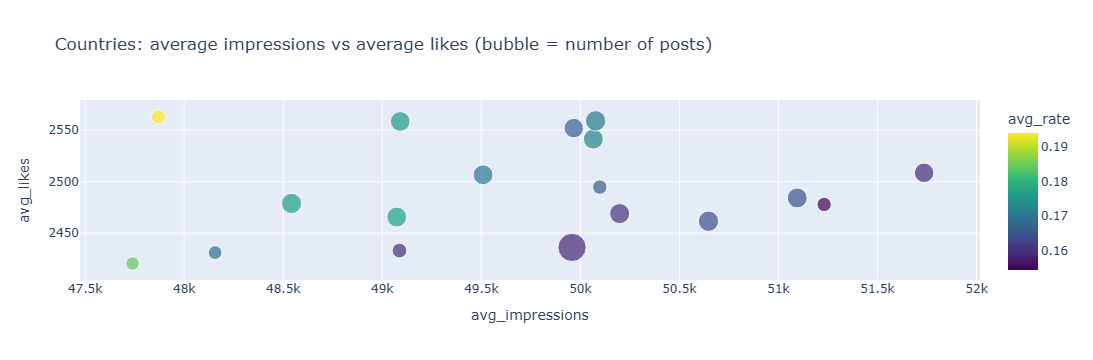

In [65]:
# Interactive bubble chart: one bubble per country
bubble = df.groupby("country", as_index=False).agg(posts=("post_id", "count"),
                                                   avg_likes=("likes_count", "mean"),
                                                   avg_impressions=("impressions", "mean"),
                                                   avg_rate=("engagement_rate_clean", "mean"))
fig = px.scatter(bubble, x="avg_impressions", y="avg_likes", size="posts", color="avg_rate",
                 hover_name="country", color_continuous_scale="Viridis",
                 title="Countries: average impressions vs average likes (bubble = number of posts)")
fig.show()

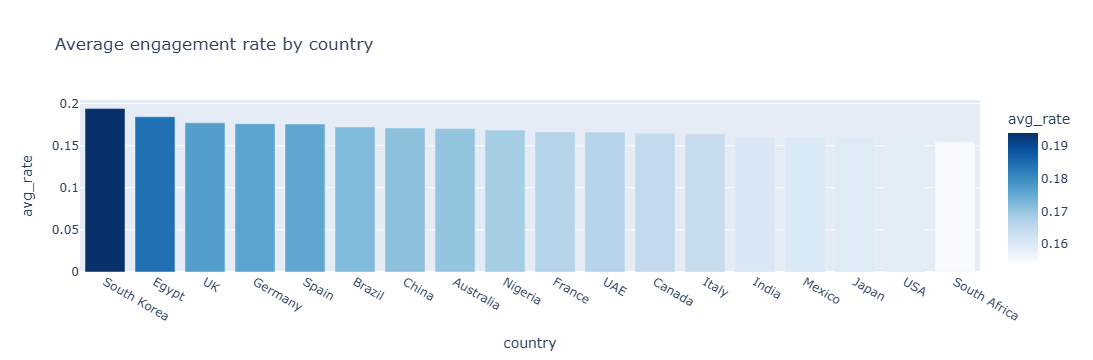

In [66]:
# Interactive bar: average engagement rate by country
bar = bubble.sort_values("avg_rate", ascending=False)
fig = px.bar(bar, x="country", y="avg_rate", color="avg_rate", color_continuous_scale="Blues",
             title="Average engagement rate by country")
fig.show()

### ❖Final Insights should Include following analysis

In [67]:
# Content performance
print("Platform (post type) - mean engagement score, mean engagement rate (capped), median rate:")
print(by_platform[["avg_engagement_score", "avg_rate", "median_rate"]].sort_values("avg_engagement_score", ascending=False))

topic = df.groupby("topic_category").agg(posts=("post_id", "count"), avg_likes=("likes_count", "mean"),
        avg_engagement_score=("engagement_score", "mean"), avg_rate=("engagement_rate_clean", "mean"),
        median_rate=("engagement_rate_clean", "median")).round(3)
print("\nTopic category:")
print(topic.sort_values("avg_engagement_score", ascending=False))

print("\nTop 5 / bottom 3 countries by average engagement rate:")
cs = by_country.sort_values("avg_rate", ascending=False)
print(cs[["posts", "avg_rate", "median_rate"]].head(5)); print(cs[["posts", "avg_rate", "median_rate"]].tail(3))

# Are the differences bigger than random noise? (one-way ANOVA / Kruskal-Wallis)
def test(col, by):
    groups = [g[col].values for _, g in df.groupby(by)]
    return stats.f_oneway(*groups).pvalue, stats.kruskal(*groups).pvalue
print("\np-values (ANOVA, Kruskal) – values above 0.05 mean the gap is within noise")
for col, by in [("engagement_score", "platform"), ("engagement_score", "topic_category"),
                ("engagement_rate_clean", "country"), ("engagement_rate_clean", "platform"),
                ("engagement_rate_clean", "topic_category")]:
    a, k = test(col, by); print(f"  {col:22s} by {by:15s}: ANOVA p={a:.3f}  Kruskal p={k:.3f}")

Platform (post type) - mean engagement score, mean engagement rate (capped), median rate:
           avg_engagement_score  avg_rate  median_rate
platform                                              
Instagram              6629.226     0.174        0.080
YouTube                6549.834     0.165        0.080
Reddit                 6514.249     0.167        0.081
Facebook               6466.641     0.170        0.082
Twitter                6447.021     0.163        0.080

Topic category:
                posts  avg_likes  avg_engagement_score  avg_rate  median_rate
topic_category                                                               
Product          1937   2498.119              6580.461     0.176        0.086
Returns          1991   2553.036              6574.819     0.169        0.082
Pricing          2046   2474.747              6525.713     0.159        0.078
Support          1947   2490.917              6516.796     0.168        0.080
Delivery         2036   2461.143        

In [68]:
# User trends (age / verified are not in the data -> closest user-level fields)
print("Correlation of user-level fields with engagement:")
print(df[["user_past_sentiment_avg", "user_engagement_growth", "engagement_rate_clean", "engagement_score",
          "impressions"]].corr().round(3).loc[["user_past_sentiment_avg", "user_engagement_growth"]])
df["growth_band"] = pd.qcut(df["user_engagement_growth"], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
print("\nEngagement by user_engagement_growth quartile:")
print(df.groupby("growth_band")[["engagement_score", "engagement_rate_clean", "impressions"]].mean().round(3))
print("\nUnique users:", df["user_id"].nunique(), "of", len(df), "posts -> every post is from a different user, so repeat-user behaviour cannot be studied.")

Correlation of user-level fields with engagement:
                         user_past_sentiment_avg  user_engagement_growth  \
user_past_sentiment_avg                    1.000                  -0.003   
user_engagement_growth                    -0.003                   1.000   

                         engagement_rate_clean  engagement_score  impressions  
user_past_sentiment_avg                 -0.008             0.002        0.012  
user_engagement_growth                  -0.013             0.006        0.011  

Engagement by user_engagement_growth quartile:
             engagement_score  engagement_rate_clean  impressions
growth_band                                                      
Q1 lowest            6493.052                  0.168    49672.048
Q2                   6539.018                  0.174    49080.989
Q3                   6548.498                  0.169    50215.448
Q4 highest           6503.089                  0.160    50277.070

Unique users: 12000 of 12000 posts -

### Behavioral Insights

Average impressions by time-of-day band:
                   impressions  engagement_score  engagement_rate_clean
time_of_day                                                            
Night (00-05)         50207.72           6558.79                   0.17
Morning (06-11)       49387.41           6495.15                   0.17
Afternoon (12-17)     48878.93           6471.60                   0.18
Evening (18-23)       50744.94           6556.75                   0.16

Best 3 hours for impressions:
hour
22    52862.0
18    52184.0
5     51918.0
Name: impressions, dtype: float64
Worst 3 hours:
hour
21    47293.0
11    47668.0
0     48136.0
Name: impressions, dtype: float64
Spread best vs worst hour: 11.8%
ANOVA p-value (impressions by hour): 0.146

Channel (platform) vs impressions (device/watch-time proxy):
           impressions  engagement_rate_clean
platform                                     
Facebook     49785.068                  0.170
Instagram    49963.597                  0.1

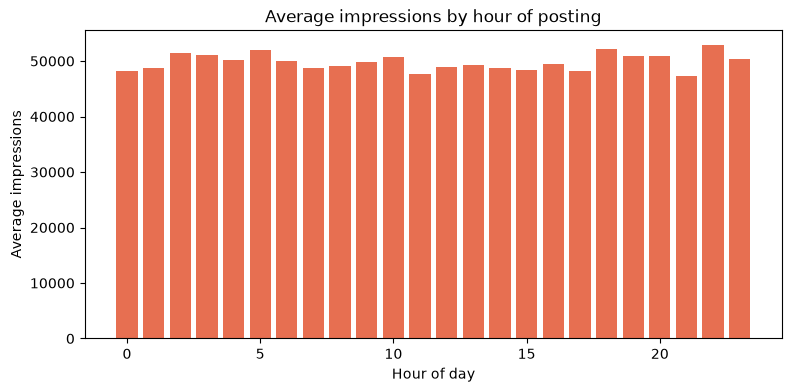

In [69]:
by_hour = df.groupby("hour")["impressions"].mean()
by_tod = df.groupby("time_of_day")[["impressions", "engagement_score", "engagement_rate_clean"]].mean().round(2)
print("Average impressions by time-of-day band:"); print(by_tod)
print("\nBest 3 hours for impressions:"); print(by_hour.sort_values(ascending=False).head(3).round(0))
print("Worst 3 hours:"); print(by_hour.sort_values().head(3).round(0))
print("Spread best vs worst hour: {:.1%}".format(by_hour.max() / by_hour.min() - 1))
print("ANOVA p-value (impressions by hour): {:.3f}".format(stats.f_oneway(*[g["impressions"].values for _, g in df.groupby("hour")]).pvalue))

print("\nChannel (platform) vs impressions (device/watch-time proxy):")
print(df.groupby("platform")[["impressions", "engagement_rate_clean"]].mean().round(3))
print("ANOVA p-value (impressions by platform): {:.3f}".format(stats.f_oneway(*[g["impressions"].values for _, g in df.groupby("platform")]).pvalue))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour.index, by_hour.values, color="#e76f51"); ax.set_xlabel("Hour of day"); ax.set_ylabel("Average impressions")
ax.set_title("Average impressions by hour of posting"); plt.show()

#### Sentiment Analysis

In [70]:
print(by_sentiment[["posts", "avg_likes", "avg_comments", "avg_shares", "avg_impressions", "avg_rate", "median_rate", "avg_toxicity"]])
print("\nShare of posts:"); print((df["sentiment_label"].value_counts(normalize=True) * 100).round(1).to_string())
print("\nEmotion mix inside each sentiment (row %):")
print((pd.crosstab(df["sentiment_label"], df["emotion_type"], normalize="index") * 100).round(1))
for col in ["engagement_score", "engagement_rate_clean", "impressions", "toxicity_score"]:
    a, k = test(col, "sentiment_label"); print(f"{col:22s} by sentiment: ANOVA p={a:.3f}  Kruskal p={k:.3f}")
print("\nCorrelation sentiment_score vs toxicity: {:.3f}".format(df["sentiment_score"].corr(df["toxicity_score"])))

                 posts  avg_likes  avg_comments  avg_shares  avg_impressions  \
sentiment_label                                                                
Negative          4854   2514.730       502.289    1007.256        49410.816   
Neutral           2307   2471.072       502.773     998.408        50606.761   
Positive          4839   2476.003       507.159    1011.254        49833.883   

                 avg_rate  median_rate  avg_toxicity  
sentiment_label                                       
Negative            0.172        0.082         0.498  
Neutral             0.165        0.078         0.509  
Positive            0.165        0.081         0.507  

Share of posts:
sentiment_label
Negative    40.4
Positive    40.3
Neutral     19.2

Emotion mix inside each sentiment (row %):
emotion_type     Angry  Confused  Excited  Happy   Sad
sentiment_label                                       
Negative          18.8      20.9     19.9   20.1  20.2
Neutral           19.8      18.